# 04 · Checkpoint 2 — Segmentación, modelo predictivo y anomalías

**Proyecto:** Búsqueda de Empleo Sin Experiencia · **Asignatura:** Minería de Datos · **Docente:** Paola Andrea Ortiz
**Integrantes:** Bryan Samuel Vélez Velásquez · Jhon Jairo Melo Largo

**Pregunta del proyecto:** ¿qué características de los jóvenes de 18 a 28 años **sin experiencia laboral** se asocian con **conseguir su primer empleo** y cómo se relacionan con la demanda de vacantes de su departamento, para decidir **qué formación recomendarles** y **hacia qué regiones y sectores orientarlos**?

Este notebook sigue donde terminó el Checkpoint 1 (`03_adquisicion_cruce.ipynb`, secciones 6 a 8). La preparación de datos (tipos, atípicos, variables derivadas, codificación y escalado) **no se repite aquí**: se importa de `preparacion.py`, que tiene exactamente las mismas funciones del notebook 03. Así los tres análisis de abajo parten del mismo dataset limpio.

| Sección | Técnica | Sobre qué |
|---|---|---|
| 1 | K-means, jerárquico y DBSCAN | Los **33 departamentos**, según cómo les va a sus jóvenes sin experiencia |
| 2 | Árbol de decisión y regresión logística | Cada joven: ¿consiguió su primer empleo (`consiguio_empleo`)? |
| 3 | Isolation Forest (anomalías) | Los **recién insertados**: primeros empleos raros por la combinación de edad, estudios e ingreso |

In [1]:
import os, sys
if "google.colab" in sys.modules and not os.path.isdir("../data/raw"):
    if not os.path.isdir("/content/Busqueda-Empleo"):
        !git clone https://github.com/samuelvelez1003/Busqueda-Empleo.git /content/Busqueda-Empleo
    %cd /content/Busqueda-Empleo/notebooks
print("Carpeta de trabajo:", os.getcwd())

Carpeta de trabajo: /home/samuel/PROJECT-WEB/Busqueda-Empleo/notebooks


## Librerías, rutas y datos del Checkpoint 1

In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from preparacion import preparar_datos, ORDEN_EDUCACION   # pipeline del Checkpoint 1 (notebook 03)

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", None)
plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .3})

for d in ["../data", "data"]:
    if os.path.isdir(d):
        DATA_DIR = d
        break
SALIDA = os.path.join(DATA_DIR, "processed")
RUTA_CRUZADO = os.path.join(SALIDA, "dataset_cruzado_sin_experiencia.csv")

X, y, pesos, datos, pipeline = preparar_datos(RUTA_CRUZADO)
print("Jóvenes sin experiencia:", len(datos))
print("Matriz X para el modelo:", X.shape, "| y:", y.value_counts().to_dict())
print("Huella de X (debe ser igual a la del notebook 03):", pd.util.hash_pandas_object(X).sum())

Jóvenes sin experiencia: 41784
Matriz X para el modelo: (41784, 16) | y: {1: 37440, 0: 4344}
Huella de X (debe ser igual a la del notebook 03): 6348956278765523075


# Sección 1 — Segmentación (Unidad 5)

**¿Qué segmentamos y por qué?** Una de las dos decisiones de la pregunta es **hacia qué regiones orientar** a los jóvenes. En el EDA vimos que la tasa de inserción cambia mucho entre departamentos (de 72 % a 97 %) y que la calidad del primer empleo también (de 11 % a 89 % de formalidad), pero mirar 33 departamentos uno por uno no sirve para decidir. Por eso segmentamos **los 33 departamentos** para encontrar unos pocos **tipos de mercado laboral juvenil**.

Segmentar a cada joven (41.784 filas) no tenía mucho sentido: sus variables numéricas son pocas y casi todas discretas (edad en años, nivel educativo), y lo que queremos orientar es **a dónde**, no a quién.

**Variables (2, como pide la guía), calculadas por departamento con el factor de expansión:**

| Variable | Qué mide | Por qué |
|---|---|---|
| `tasa_insercion` | % de jóvenes sin experiencia que consiguieron su primer empleo | ¿Es fácil **entrar**? |
| `pct_formal` | De los que entraron, % con empleo formal (cotizan a pensión) | ¿Ese primer empleo es **bueno**? |

Las dos se **escalan** con `StandardScaler` (media 0, desviación 1), como en la Unidad 4. Están en la misma unidad (%), pero la formalidad varía mucho más que la inserción, y sin escalar dominaría el cálculo de distancias.

In [3]:
from sklearn.preprocessing import StandardScaler

def promedio_ponderado(g, columna):
    validos = g[columna].notna()
    return np.average(g.loc[validos, columna].astype(float), weights=g.loc[validos, "factor_expansion"])

def resumen_departamentos(datos):
    filas = []
    for (codigo, nombre), g in datos.groupby(["codigo_departamento", "departamento"], observed=True):
        insertados = g[g["consiguio_empleo"] == 1]
        filas.append({
            "codigo_departamento": codigo, "departamento": nombre, "n_muestra": len(g),
            "tasa_insercion": promedio_ponderado(g, "consiguio_empleo") * 100,
            "pct_formal": promedio_ponderado(insertados, "empleo_formal") * 100,
            "pct_vacantes_sin_experiencia": g["pct_vacantes_sin_experiencia"].iloc[0],
            "vacantes_sin_exp_por_1000": g["vacantes_sin_exp_por_1000"].iloc[0],
        })
    return pd.DataFrame(filas)

deptos = resumen_departamentos(datos)
VARIABLES_SEG = ["tasa_insercion", "pct_formal"]
escalador = StandardScaler()
Z = escalador.fit_transform(deptos[VARIABLES_SEG])

print("Departamentos:", len(deptos))
deptos.sort_values("tasa_insercion").round(1)

Departamentos: 33


,codigo_departamento,departamento,n_muestra,tasa_insercion,pct_formal,pct_vacantes_sin_experiencia,vacantes_sin_exp_por_1000
29,94,Guainía,81,72.1,26.1,4.9,48.0
28,91,Amazonas,37,76.4,59.1,10.0,666.6
11,27,Chocó,940,80.0,22.3,14.7,18.8
3,13,Bolívar,1598,80.6,31.7,9.0,35.9
24,81,Arauca,237,80.8,40.4,31.1,427.8
21,70,Sucre,1297,83.6,13.0,16.5,24.5
12,41,Huila,1184,83.6,35.2,14.4,80.4
13,44,La Guajira,1224,84.6,29.8,14.3,24.2
9,23,Córdoba,1329,86.4,11.2,18.4,19.0
1,08,Atlántico,1747,86.8,41.8,12.2,63.4


### 1.1 ¿Cuántos grupos? Método del codo y coeficiente de silueta

- **Codo:** la inercia (qué tan lejos quedan los departamentos del centro de su grupo) siempre baja al agregar grupos; buscamos el punto donde deja de bajar fuerte.
- **Silueta:** de −1 a 1, qué tan bien queda cada departamento en su grupo comparado con el grupo vecino. Más alto es mejor.
- Además miramos el **tamaño del grupo más pequeño**: un grupo de un solo departamento no es un "tipo de mercado", es un caso aislado.

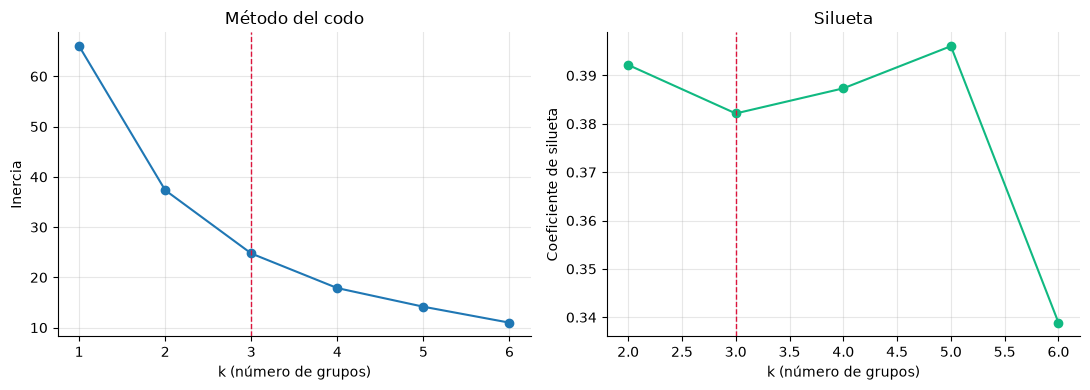

,inercia,silueta,grupo_mas_pequeno
k,,,
1,66.000,NaN,33
2,37.344,0.392,16
3,24.752,0.382,8
4,17.868,0.387,1
5,14.163,0.396,1
6,10.990,0.339,1


In [4]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

filas = []
for k in range(1, 7):
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(Z)
    filas.append({"k": k, "inercia": km.inertia_,
                  "silueta": silhouette_score(Z, km.labels_) if k > 1 else np.nan,
                  "grupo_mas_pequeno": np.bincount(km.labels_).min()})
eleccion_k = pd.DataFrame(filas).set_index("k")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(eleccion_k.index, eleccion_k["inercia"], marker="o")
ax[0].axvline(3, color="crimson", ls="--", lw=1)
ax[0].set_xlabel("k (número de grupos)")
ax[0].set_ylabel("Inercia")
ax[0].set_title("Método del codo")
ax[1].plot(eleccion_k.index[1:], eleccion_k["silueta"].iloc[1:], marker="o", color="#10b981")
ax[1].axvline(3, color="crimson", ls="--", lw=1)
ax[1].set_xlabel("k (número de grupos)")
ax[1].set_ylabel("Coeficiente de silueta")
ax[1].set_title("Silueta")
plt.tight_layout()
plt.show()
eleccion_k.round(3)

**Elegimos k = 3.**

- **Codo:** la inercia cae de **66,0** (k=1) a **37,3** (k=2) y a **24,8** (k=3). Desde ahí las bajadas son más pequeñas (17,9 → 14,2 → 11,0): el codo está en **k = 3**.
- **Silueta:** entre k=2 y k=5 está prácticamente empatada (**0,38 a 0,40**) y cae con k=6 (0,34). No señala un k claro, así que no contradice al codo. Es una separación **moderada**: los departamentos no forman grupos perfectamente aislados, sino un continuo con zonas.
- **Tamaño:** con k=4 aparece un grupo de **un solo departamento** (San Andrés, con 89 % de formalidad). k=3 es el número más grande en el que todos los grupos son tipos de mercado, no casos aislados.
- k=2 sería más simple, pero junta a los departamentos donde **cuesta entrar** con los que **entran pero a la informalidad**, que necesitan acciones distintas.

### 1.2 K-means con k = 3

In [5]:
K = 3
kmeans = KMeans(n_clusters=K, n_init=10, random_state=42).fit(Z)
deptos["cluster"] = kmeans.labels_

# Nombre de cada grupo según sus promedios (así no depende del número que le ponga K-means)
centros = deptos.groupby("cluster")[VARIABLES_SEG].mean()
c_bajo = centros["tasa_insercion"].idxmin()
resto = centros.drop(c_bajo)
c_formal, c_informal = resto["pct_formal"].idxmax(), resto["pct_formal"].idxmin()
NOMBRES = {c_formal: "A · Entran y con empleo formal",
           c_bajo: "B · Cuesta entrar",
           c_informal: "C · Entran, pero a la informalidad"}
deptos["segmento"] = deptos["cluster"].map(NOMBRES)

perfil = deptos.groupby("segmento").agg(
    departamentos=("departamento", "count"),
    tasa_insercion=("tasa_insercion", "mean"),
    pct_formal=("pct_formal", "mean"),
    pct_vacantes_sin_experiencia=("pct_vacantes_sin_experiencia", "mean"),
    vacantes_sin_exp_por_1000=("vacantes_sin_exp_por_1000", "median"),
    jovenes_en_muestra=("n_muestra", "sum"),
).round(1)
perfil

,departamentos,tasa_insercion,pct_formal,pct_vacantes_sin_experiencia,vacantes_sin_exp_por_1000,jovenes_en_muestra
segmento,,,,,,
A · Entran y con empleo formal,15,93.5,49.7,18.6,121.0,21284
B · Cuesta entrar,8,80.6,35.8,13.8,55.7,7048
"C · Entran, pero a la informalidad",10,90.0,21.5,14.7,27.4,13452


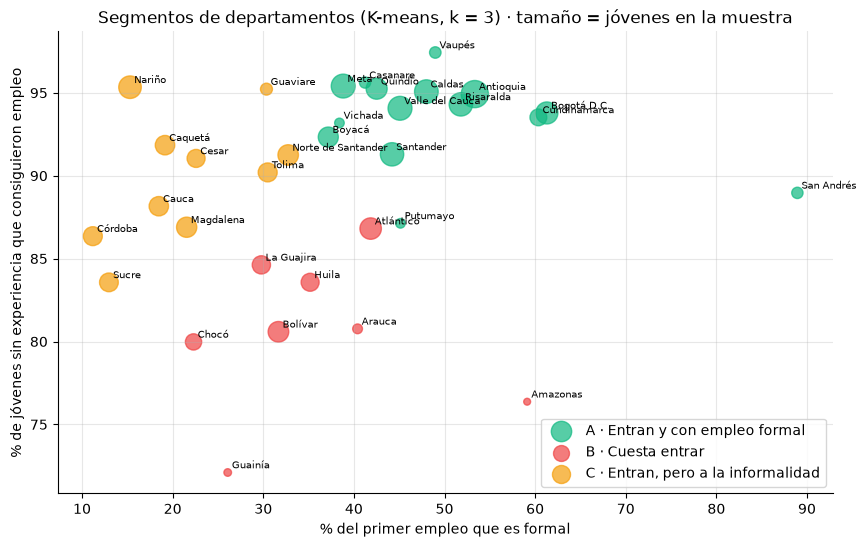

A · Entran y con empleo formal (15): Vaupés, Casanare, Meta, Quindío, Caldas, Antioquia, Risaralda, Valle del Cauca, Bogotá D.C., Cundinamarca, Vichada, Boyacá, Santander, San Andrés, Putumayo
B · Cuesta entrar (8): Atlántico, La Guajira, Huila, Arauca, Bolívar, Chocó, Amazonas, Guainía
C · Entran, pero a la informalidad (10): Nariño, Guaviare, Caquetá, Norte de Santander, Cesar, Tolima, Cauca, Magdalena, Córdoba, Sucre


In [6]:
COLORES_SEG = {"A · Entran y con empleo formal": "#10b981", "B · Cuesta entrar": "#ef4444",
               "C · Entran, pero a la informalidad": "#f59e0b"}

fig, ax = plt.subplots(figsize=(10, 6))
for seg, g in deptos.groupby("segmento"):
    ax.scatter(g["pct_formal"], g["tasa_insercion"], s=g["n_muestra"] / 8 + 20, alpha=.7,
               color=COLORES_SEG[seg], label=seg)
for _, r in deptos.iterrows():
    ax.annotate(r["departamento"], (r["pct_formal"], r["tasa_insercion"]), fontsize=7,
                xytext=(3, 3), textcoords="offset points")
ax.set_xlabel("% del primer empleo que es formal")
ax.set_ylabel("% de jóvenes sin experiencia que consiguieron empleo")
ax.set_title("Segmentos de departamentos (K-means, k = 3) · tamaño = jóvenes en la muestra")
ax.legend(loc="lower right")
plt.show()

for seg, g in deptos.sort_values("tasa_insercion", ascending=False).groupby("segmento"):
    print(f"{seg} ({len(g)}): {', '.join(g['departamento'])}")

**Interpretación de cada grupo:**

- **A · Entran y con empleo formal (15 departamentos; 93,5 % de inserción, 50 % de formalidad).** Son los mercados más fuertes para un joven sin experiencia: el centro y el Eje Cafetero (Bogotá, Antioquia, Valle, Caldas, Risaralda, Quindío, Santander, Cundinamarca, Boyacá), varios de los Llanos y la Amazonía (Meta, Casanare, Vichada, Vaupés, Putumayo) y San Andrés. Casi todos entran, y la mitad lo hace con contrato y pensión.
- **B · Cuesta entrar (8 departamentos; 80,6 % de inserción, 36 % de formalidad).** Sobre todo el Caribe (Atlántico, Bolívar, La Guajira), Chocó y Huila, más Arauca, Amazonas y Guainía. Aquí **1 de cada 5** jóvenes sin experiencia que busca no ha conseguido su primer empleo, tres veces más que en el grupo A (6,5 %).
- **C · Entran, pero a la informalidad (10 departamentos; 90 % de inserción, solo 22 % de formalidad).** Sur y Caribe interior (Nariño, Cauca, Córdoba, Sucre, Magdalena, Cesar, Tolima…). Conseguir el primer trabajo no es el problema: **casi 4 de cada 5 entran sin cotizar a pensión**.

**Para la decisión:** el grupo B necesita programas de **primer empleo** (prácticas, aprendizaje, intermediación). El grupo C necesita **formalización** y formación técnica que dé acceso a empleos formales (el hallazgo 2 del EDA mostró que la formalidad sube de 38 % con bachiller a 59 % con técnico). Al grupo A es hacia donde **conviene orientar** a quien pueda moverse.

### 1.3 Comparación con clustering jerárquico

Mismas 2 variables escaladas, enlace de Ward (une los grupos que menos aumentan la varianza interna, que es lo mismo que optimiza K-means). El dendrograma permite ver si 3 grupos es un corte natural.

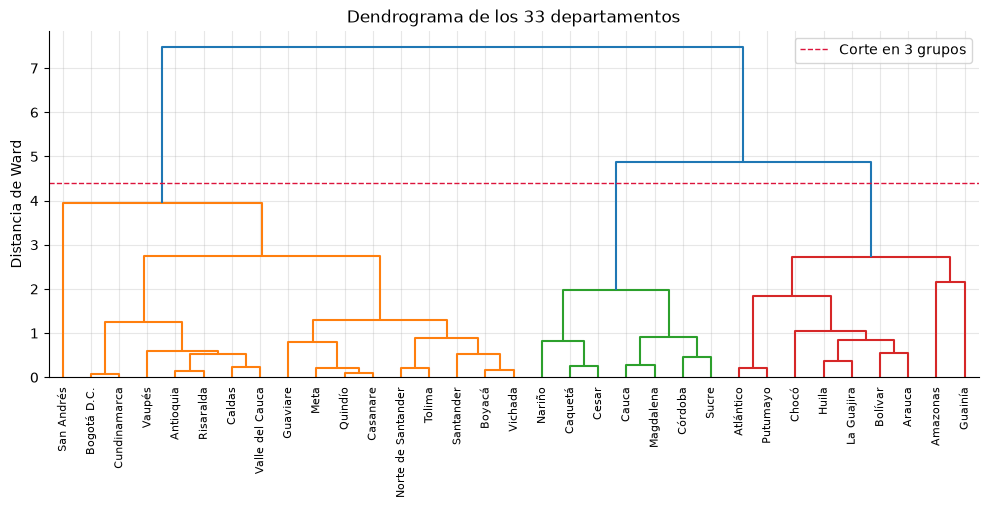

Departamentos que quedan en el mismo grupo con los dos métodos: 29 de 33


cluster_jerarquico,0,1,2
segmento,,,
A · Entran y con empleo formal,14,1,0
B · Cuesta entrar,0,8,0
"C · Entran, pero a la informalidad",3,0,7


In [7]:
from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, linkage

fig, ax = plt.subplots(figsize=(12, 4.5))
dendrogram(linkage(Z, method="ward"), labels=deptos["departamento"].tolist(), leaf_rotation=90,
           leaf_font_size=8, color_threshold=4.4, ax=ax)
ax.axhline(4.4, color="crimson", ls="--", lw=1, label="Corte en 3 grupos")
ax.set_ylabel("Distancia de Ward")
ax.set_title("Dendrograma de los 33 departamentos")
ax.legend()
plt.show()

jerarquico = AgglomerativeClustering(n_clusters=K, linkage="ward").fit_predict(Z)
deptos["cluster_jerarquico"] = jerarquico
tabla = pd.crosstab(deptos["segmento"], deptos["cluster_jerarquico"])
coinciden = tabla.max(axis=1).sum()
print(f"Departamentos que quedan en el mismo grupo con los dos métodos: {coinciden} de {len(deptos)}")
tabla

In [8]:
# ¿Cuáles cambian de grupo?
grupo_mayoritario = tabla.idxmax(axis=1)
cambian = deptos[deptos["cluster_jerarquico"] != deptos["segmento"].map(grupo_mayoritario)]
cambian[["departamento", "segmento", "cluster_jerarquico", "tasa_insercion", "pct_formal"]].round(1)

,departamento,segmento,cluster_jerarquico,tasa_insercion,pct_formal
17,Norte de Santander,"C · Entran, pero a la informalidad",0,91.3,32.7
22,Tolima,"C · Entran, pero a la informalidad",0,90.2,30.5
26,Putumayo,A · Entran y con empleo formal,1,87.1,45.1
30,Guaviare,"C · Entran, pero a la informalidad",0,95.2,30.3


**Lectura:** el jerárquico confirma la segmentación: **29 de 33** departamentos quedan en el mismo grupo. Los que cambian están en la **frontera** entre dos grupos (inserción alta pero formalidad intermedia), así que su asignación es la menos segura. Que dos métodos distintos lleguen casi a lo mismo nos da confianza en que los 3 tipos no son un accidente de K-means.

### 1.4 Comparación con DBSCAN

DBSCAN no recibe el número de grupos: busca zonas densas y marca como **ruido (−1)** a los puntos sueltos. Probamos varios `eps` (radio de vecindad, en unidades escaladas) con `min_samples = 3`, buscando un resultado interpretable: ni todo en un grupo ni todo ruido.

In [9]:
from sklearn.cluster import DBSCAN

pruebas = []
for eps in [0.4, 0.5, 0.6, 0.7, 0.8, 1.0]:
    etiquetas = DBSCAN(eps=eps, min_samples=3).fit_predict(Z)
    pruebas.append({"eps": eps, "grupos": len(set(etiquetas) - {-1}), "ruido": int((etiquetas == -1).sum()),
                    "departamentos_ruido": ", ".join(deptos.loc[etiquetas == -1, "departamento"])})
pd.DataFrame(pruebas)

,eps,grupos,ruido,departamentos_ruido
0,0.4,1,21,"Atlántico, Bogotá D.C., Bolívar, Caquetá, Cauc..."
1,0.5,1,18,"Atlántico, Bolívar, Caquetá, Cauca, Cesar, Cór..."
2,0.6,2,6,"Atlántico, Nariño, Putumayo, San Andrés, Amazo..."
3,0.7,1,3,"San Andrés, Amazonas, Guainía"
4,0.8,1,3,"San Andrés, Amazonas, Guainía"
5,1.0,1,3,"San Andrés, Amazonas, Guainía"


In [10]:
deptos["cluster_dbscan"] = DBSCAN(eps=0.7, min_samples=3).fit_predict(Z)
print(deptos["cluster_dbscan"].value_counts().rename({-1: "ruido"}))
deptos.loc[deptos["cluster_dbscan"] == -1, ["departamento", "n_muestra", "tasa_insercion", "pct_formal", "segmento"]].round(1)

cluster_dbscan
0        30
ruido     3
Name: count, dtype: int64


,departamento,n_muestra,tasa_insercion,pct_formal,segmento
27,San Andrés,371,89.0,88.9,A · Entran y con empleo formal
28,Amazonas,37,76.4,59.1,B · Cuesta entrar
29,Guainía,81,72.1,26.1,B · Cuesta entrar


**Lectura:** con `eps` de 0,4 y 0,5 DBSCAN marca como ruido a más de la mitad de los departamentos (21 y 18); con 0,6 arma un segundo grupo pequeño y deja 6 como ruido; y desde `eps = 0,7` junta a **30 en un solo grupo** y deja **3 como ruido: San Andrés, Amazonas y Guainía**. Es decir, DBSCAN **no ve grupos separados por densidad**: los departamentos forman una nube continua (lo mismo que dijo la silueta moderada). Lo que sí aporta es una **alerta**:

- **Amazonas (37 encuestados) y Guainía (81)** tienen tasas muy bajas (76 % y 72 %), pero con tan pocos jóvenes en la muestra no son confiables. En el EDA ya los habíamos dejado por fuera de las conclusiones.
- **San Andrés** es un caso aparte: una isla con **89 % de formalidad**, muy por encima de todos los demás.

Por eso, en el grupo B, Amazonas y Guainía se reportan con advertencia.

### 1.5 Reto opcional (opción 2): ¿qué pasa si agregamos una tercera variable?

Agregamos `pct_vacantes_sin_experiencia` (SPE): el % de vacantes del departamento que **no piden experiencia**. Es la variable que cruza las dos fuentes.

In [11]:
VARIABLES_3 = VARIABLES_SEG + ["pct_vacantes_sin_experiencia"]
Z3 = StandardScaler().fit_transform(deptos[VARIABLES_3])

silueta_3 = {k: silhouette_score(Z3, KMeans(n_clusters=k, n_init=10, random_state=42).fit_predict(Z3)) for k in range(2, 7)}
print("Silueta con 3 variables:", {k: round(v, 3) for k, v in silueta_3.items()})

deptos["cluster_3var"] = KMeans(n_clusters=3, n_init=10, random_state=42).fit_predict(Z3)
print(deptos.groupby("cluster_3var")[VARIABLES_3].mean().round(1))
for c, g in deptos.groupby("cluster_3var"):
    print(f"Grupo {c} ({len(g)}): {', '.join(g['departamento'])}")
pd.crosstab(deptos["segmento"], deptos["cluster_3var"])

Silueta con 3 variables: {2: 0.296, 3: 0.355, 4: 0.322, 5: 0.317, 6: 0.261}
              tasa_insercion  pct_formal  pct_vacantes_sin_experiencia
cluster_3var                                                          
0                       82.2        26.8                          12.8
1                       93.3        40.1                          14.2
2                       88.1        53.9                          34.9
Grupo 0 (10): Bolívar, Cauca, Córdoba, Chocó, Huila, La Guajira, Magdalena, Sucre, Amazonas, Guainía
Grupo 1 (19): Antioquia, Atlántico, Bogotá D.C., Boyacá, Caldas, Caquetá, Cesar, Cundinamarca, Meta, Nariño, Norte de Santander, Quindío, Risaralda, Santander, Tolima, Valle del Cauca, Guaviare, Vaupés, Vichada
Grupo 2 (4): Arauca, Casanare, Putumayo, San Andrés


cluster_3var,0,1,2
segmento,,,
A · Entran y con empleo formal,0,12,3
B · Cuesta entrar,6,1,1
"C · Entran, pero a la informalidad",4,6,0


**Lectura:** con 3 variables la silueta sí tiene un máximo claro en **k = 3 (0,355)**, pero los grupos **cambian**. La tercera variable separa a **Arauca, Casanare, Putumayo y San Andrés**, donde **más de 30 %** de las vacantes no piden experiencia (el resto del país está entre 5 % y 24 %). Esos 4 departamentos tienen pocos jóvenes y mucha vacante por joven, y el resto se reparte entre "inserción alta" y "inserción baja".

Nos quedamos con la segmentación de **2 variables** para la decisión, porque es la que responde directamente "¿entran?" y "¿entran bien?". Este reto muestra que **el % de vacantes sin experiencia no explica la inserción**: los departamentos que más vacantes sin experiencia ofrecen quedan en un grupo propio, pero su inserción es parecida a la del resto (88 % en promedio). Es el mismo resultado del EDA (Spearman = 0,03).

### 1.6 Reto opcional (opción 3): ¿qué técnica sirve más para nuestra pregunta?

- **K-means:** la más útil. Da 3 tipos de departamento con un perfil claro y una acción distinta para cada uno.
- **Jerárquico:** sirve para **validar**. El dendrograma muestra que 3 es un corte razonable, y coincide con K-means en 29 de 33 casos.
- **DBSCAN:** no sirve para formar grupos con estos datos (la nube es continua), pero sí para **detectar departamentos atípicos** que no se deben usar para decidir sin más datos (Amazonas, Guainía).

> **Reglas de asociación (Apriori):** no aplican a nuestro proyecto. La GEIH tiene una fila por persona con atributos fijos, no "canastas" de varios ítems registrados juntos.

In [12]:
deptos.to_csv(os.path.join(SALIDA, "segmentos_departamentos.csv"), index=False)
print("Guardado: data/processed/segmentos_departamentos.csv")

Guardado: data/processed/segmentos_departamentos.csv


# Sección 2 — Modelo predictivo y evaluación (Unidad 6)

**Qué predecimos:** `consiguio_empleo` (**clasificación** binaria).

| Valor | Quién es | Muestra |
|---|---|---|
| 1 | **Recién insertado:** consiguió su primer empleo en los últimos 12 meses | 37.440 (89,6 %) |
| 0 | **Aspirante:** busca empleo y nunca ha trabajado | 4.344 (10,4 %) |

**Para qué serviría:** con los datos de un joven que **todavía no tiene empleo** (edad, estudios, si estudia, dónde vive y cómo es la demanda de su departamento), estimar si está en riesgo de **quedarse como aspirante**, para priorizarlo en orientación. Por eso la clase que más nos importa detectar es la **0 (aspirante)**.

**Variables de entrada:** la matriz `X` del Checkpoint 1 (16 columnas): `edad`, `nivel_educativo_grupo`, `sexo`, `zona`, `grupo_edad`, `estudia_actualmente`, `formacion_practica`, `vive_en_capital`, `pct_vacantes_su_nivel`, `pct_vacantes_sin_experiencia` y `log_vacantes_sin_exp_por_1000`. **Ya vienen sin las variables que delatan la respuesta** (sección 8.1 del notebook 03). En 2.4 lo comprobamos.

### 2.1 Separar entrenamiento y prueba

In [13]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)
print("Entrenamiento:", X_train.shape, "| prueba:", X_test.shape)
print("%% de aspirantes (clase 0) → entrenamiento: %.1f %% | prueba: %.1f %%"
      % ((y_train == 0).mean() * 100, (y_test == 0).mean() * 100))

Entrenamiento: (29248, 16) | prueba: (12536, 16)
% de aspirantes (clase 0) → entrenamiento: 10.4 % | prueba: 10.4 %


`stratify=y` mantiene la misma proporción de aspirantes (≈10 %) en las dos partes. El 30 % de prueba (12.536 jóvenes) **nunca** se usa para entrenar.

### 2.2 Línea base: un modelo "tonto" y el primer árbol

Como 9 de cada 10 jóvenes son recién insertados, un modelo que **siempre** responda "sí consiguió empleo" ya acierta el 89,6 %. Cualquier modelo tiene que compararse contra eso.

In [14]:
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, confusion_matrix, f1_score,
                             precision_score, recall_score, roc_auc_score, classification_report)

def evaluar(modelo, nombre, Xtr=X_train, Xte=X_test):
    # Entrena y devuelve las métricas de entrenamiento y prueba. La clase que nos interesa es 0 (aspirante).
    modelo.fit(Xtr, y_train)
    p_tr, p_te = modelo.predict(Xtr), modelo.predict(Xte)
    return {
        "modelo": nombre,
        "accuracy_entrenamiento": accuracy_score(y_train, p_tr),
        "accuracy_prueba": accuracy_score(y_test, p_te),
        "precision_aspirante": precision_score(y_test, p_te, pos_label=0, zero_division=0),
        "recall_aspirante": recall_score(y_test, p_te, pos_label=0),
        "f1_aspirante": f1_score(y_test, p_te, pos_label=0),
        "f1_insertado": f1_score(y_test, p_te, pos_label=1),
        "accuracy_balanceada": balanced_accuracy_score(y_test, p_te),
        "auc": roc_auc_score(y_test, modelo.predict_proba(Xte)[:, 1]),
    }

resultados = [
    evaluar(DummyClassifier(strategy="most_frequent"), "Siempre dice 'sí consiguió'"),
    evaluar(DecisionTreeClassifier(max_depth=4, random_state=42), "Árbol max_depth=4"),
]
pd.DataFrame(resultados).set_index("modelo").round(3)

,accuracy_entrenamiento,accuracy_prueba,precision_aspirante,recall_aspirante,f1_aspirante,f1_insertado,accuracy_balanceada,auc
modelo,,,,,,,,
Siempre dice 'sí consiguió',0.896,0.896,0.0,0.0,0.0,0.945,0.5,0.500
Árbol max_depth=4,0.896,0.896,0.0,0.0,0.0,0.945,0.5,0.674


**Lectura:** el primer árbol (el de la guía, `max_depth=4`) tiene **89,6 % de accuracy**, exactamente igual al modelo tonto, y **no detecta ni un solo aspirante** (recall = 0). Aprendió que decir siempre "sí" es lo que más acierta. Es el problema del **desbalance**: el accuracy alto engaña.

### 2.3 Árbol con clases balanceadas

Con `class_weight="balanced"` cada aspirante pesa en el entrenamiento lo mismo que ~9 insertados, así que equivocarse con un aspirante le cuesta lo mismo al modelo que equivocarse con nueve insertados.

In [15]:
arbol = DecisionTreeClassifier(max_depth=4, class_weight="balanced", random_state=42)
resultados.append(evaluar(arbol, "Árbol max_depth=4 balanceado"))
pred_test = arbol.predict(X_test)

print(classification_report(y_test, pred_test, target_names=["0 · Aspirante", "1 · Insertado"], digits=3))

matriz = pd.DataFrame(confusion_matrix(y_test, pred_test),
                      index=["Real: aspirante", "Real: insertado"],
                      columns=["Predijo: aspirante", "Predijo: insertado"])
matriz

               precision    recall  f1-score   support

0 · Aspirante      0.151     0.705     0.249      1303
1 · Insertado      0.941     0.541     0.687     11233

     accuracy                          0.558     12536
    macro avg      0.546     0.623     0.468     12536
 weighted avg      0.859     0.558     0.641     12536



,Predijo: aspirante,Predijo: insertado
Real: aspirante,919,384
Real: insertado,5155,6078


**Lectura de la matriz de confusión (12.536 jóvenes de prueba):**

- De los **1.303 aspirantes reales**, el modelo detecta **919 (recall 70,5 %)** y se le escapan 384.
- Pero para atraparlos marca como aspirantes a **5.155 jóvenes que sí consiguieron empleo**: de cada 100 que señala, solo **15 son aspirantes de verdad (precisión 15,1 %)**.
- El accuracy baja a **55,8 %**, pero ahora el modelo **sí distingue algo**: la accuracy balanceada es **62,3 %** (frente a 50 % del modelo tonto) y el AUC es **0,67**.

Es un modelo **débil**. Tiene sentido: con edad, estudios y departamento no se puede saber si a alguien lo van a contratar, porque faltan cosas que la encuesta no mide (contactos, habilidades, disponibilidad, a cuántas vacantes aplicó).

### 2.4 Revisión de fuga de datos

**¿Alguna variable de entrada fue usada para construir la respuesta?** `consiguio_empleo` se construyó en `02_limpieza` así: **1** si el joven es ocupado con ≤ 12 meses en su empleo, **0** si es desocupado que nunca ha trabajado. Entonces cualquier variable que **solo exista para uno de los dos grupos** delata la respuesta:

| Variable | Solo existe para | ¿Está en `X`? |
|---|---|---|
| `semanas_buscando` | Aspirantes | **No** |
| `ingreso_laboral_mensual`, `sector`, `tipo_contrato`, `posicion_ocupacional`, `empleo_formal` | Insertados | **No** |
| `meses_en_empleo_actual` | Insertados (se usó en la definición) | **No** |
| `condicion` (ocupado / desocupado) | Es la respuesta misma | **No** |

Para mostrar qué pasaría si se colaran, entrenamos el mismo árbol **agregando** `semanas_buscando` e ingreso (con 0 donde no existen):

In [16]:
X_fuga = X.copy()
X_fuga["semanas_buscando"] = datos["semanas_buscando"].fillna(0).values
X_fuga["ingreso_laboral_mensual"] = datos["ingreso_laboral_mensual"].fillna(0).values
Xf_train, Xf_test = X_fuga.loc[X_train.index], X_fuga.loc[X_test.index]

arbol_fuga = DecisionTreeClassifier(max_depth=4, class_weight="balanced", random_state=42)
r = evaluar(arbol_fuga, "CON FUGA (semanas buscando + ingreso)", Xf_train, Xf_test)
print("Accuracy de prueba con fuga: %.1f %%" % (r["accuracy_prueba"] * 100))
print("\nImportancia de variables del árbol con fuga:")
print(pd.Series(arbol_fuga.feature_importances_, index=X_fuga.columns).sort_values(ascending=False).head(4).round(3))

Accuracy de prueba con fuga: 99.8 %

Importancia de variables del árbol con fuga:
semanas_buscando           0.996
ingreso_laboral_mensual    0.002
pct_vacantes_su_nivel      0.001
grupo_edad_21-24           0.001
dtype: float64


In [17]:
print("Importancia de variables del árbol SIN fuga (el de 2.3):")
pd.Series(arbol.feature_importances_, index=X.columns).sort_values(ascending=False).head(6).round(3)

Importancia de variables del árbol SIN fuga (el de 2.3):


edad                             0.456
log_vacantes_sin_exp_por_1000    0.260
nivel_educativo_grupo            0.239
pct_vacantes_sin_experiencia     0.032
sexo_Hombre                      0.013
pct_vacantes_su_nivel            0.000
dtype: float64

**Lectura:** con fuga, el árbol "acierta" el **99,8 %**, y casi toda la decisión (**99,6 % de la importancia**) es una sola pregunta: *¿semanas buscando > 0?* No predice nada: repite la regla con la que se construyó la respuesta (si tiene semanas buscando es porque es aspirante). Además, en la vida real no serviría, porque al joven que queremos evaluar todavía no le podemos preguntar su ingreso del primer empleo.

Sin fuga, la importancia está repartida entre **edad (46 %)**, **vacantes sin experiencia por cada 1.000 jóvenes del departamento (26 %)** y **nivel educativo (24 %)**. Son variables que sí conocemos **antes** de que el joven consiga empleo, y coinciden con los hallazgos del EDA: la edad era la variable que más separaba (hallazgo 3).

### 2.5 Entrenamiento vs. prueba: ¿hay sobreajuste? (reto opcional, opción 2)

Probamos distintas profundidades del árbol balanceado.

In [18]:
profundidades = []
for prof in [2, 4, 8, None]:
    r = evaluar(DecisionTreeClassifier(max_depth=prof, class_weight="balanced", random_state=42),
                f"Árbol balanceado max_depth={prof}")
    profundidades.append(r)
tabla_prof = pd.DataFrame(profundidades).set_index("modelo")
tabla_prof["diferencia_accuracy"] = tabla_prof["accuracy_entrenamiento"] - tabla_prof["accuracy_prueba"]
tabla_prof.round(3)

,accuracy_entrenamiento,accuracy_prueba,precision_aspirante,recall_aspirante,f1_aspirante,f1_insertado,accuracy_balanceada,auc,diferencia_accuracy
modelo,,,,,,,,,
Árbol balanceado max_depth=2,0.438,0.430,0.127,0.763,0.218,0.552,0.577,0.617,0.008
Árbol balanceado max_depth=4,0.570,0.558,0.151,0.705,0.249,0.687,0.623,0.672,0.012
Árbol balanceado max_depth=8,0.643,0.629,0.175,0.692,0.279,0.750,0.657,0.710,0.015
Árbol balanceado max_depth=None,0.779,0.704,0.173,0.487,0.255,0.816,0.608,0.621,0.075


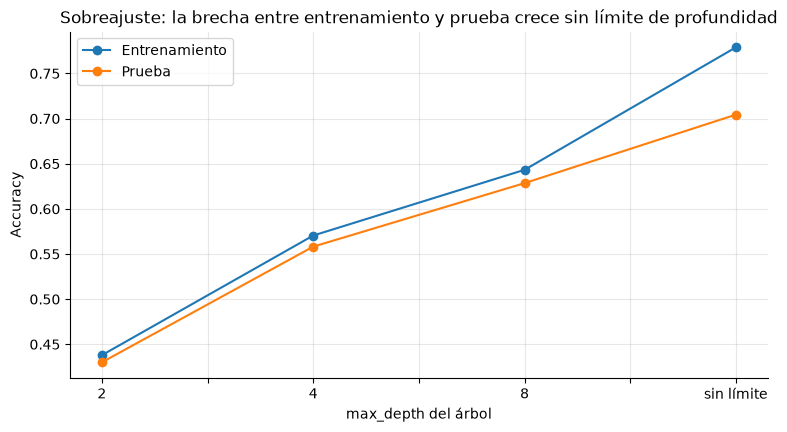

In [19]:
etiquetas = ["2", "4", "8", "sin límite"]
ax = pd.DataFrame({"Entrenamiento": tabla_prof["accuracy_entrenamiento"].values,
                   "Prueba": tabla_prof["accuracy_prueba"].values}, index=etiquetas).plot(marker="o")
ax.set_xlabel("max_depth del árbol")
ax.set_ylabel("Accuracy")
ax.set_title("Sobreajuste: la brecha entre entrenamiento y prueba crece sin límite de profundidad")
plt.show()

**Lectura:**

- Con **profundidad 2, 4 y 8** la diferencia entre entrenamiento y prueba es **menor a 1,5 puntos** (0,8; 1,2 y 1,5): no hay sobreajuste.
- **Sin límite**, el árbol llega a **77,9 %** en entrenamiento y cae a **70,4 %** en prueba (7,5 puntos de brecha). Además su AUC baja a 0,62 y detecta menos aspirantes (recall 48,7 %): **memorizó** combinaciones de la muestra que no se repiten.
- **Profundidad 8** es la mejor: el AUC más alto (**0,71**), la mejor accuracy balanceada (**65,7 %**) y una brecha pequeña.

### 2.6 Segundo modelo: regresión logística (reto opcional, opción 1)

In [20]:
from sklearn.linear_model import LogisticRegression

logistica = LogisticRegression(max_iter=1000, class_weight="balanced")
resultados_finales = [
    evaluar(DummyClassifier(strategy="most_frequent"), "Siempre dice 'sí consiguió'"),
    evaluar(DecisionTreeClassifier(max_depth=4, class_weight="balanced", random_state=42), "Árbol balanceado max_depth=4"),
    evaluar(DecisionTreeClassifier(max_depth=8, class_weight="balanced", random_state=42), "Árbol balanceado max_depth=8"),
    evaluar(logistica, "Regresión logística balanceada"),
]
comparacion = pd.DataFrame(resultados_finales).set_index("modelo")
comparacion.round(3)

,accuracy_entrenamiento,accuracy_prueba,precision_aspirante,recall_aspirante,f1_aspirante,f1_insertado,accuracy_balanceada,auc
modelo,,,,,,,,
Siempre dice 'sí consiguió',0.896,0.896,0.000,0.000,0.000,0.945,0.500,0.500
Árbol balanceado max_depth=4,0.570,0.558,0.151,0.705,0.249,0.687,0.623,0.672
Árbol balanceado max_depth=8,0.643,0.629,0.175,0.692,0.279,0.750,0.657,0.710
Regresión logística balanceada,0.627,0.622,0.167,0.661,0.267,0.746,0.639,0.689


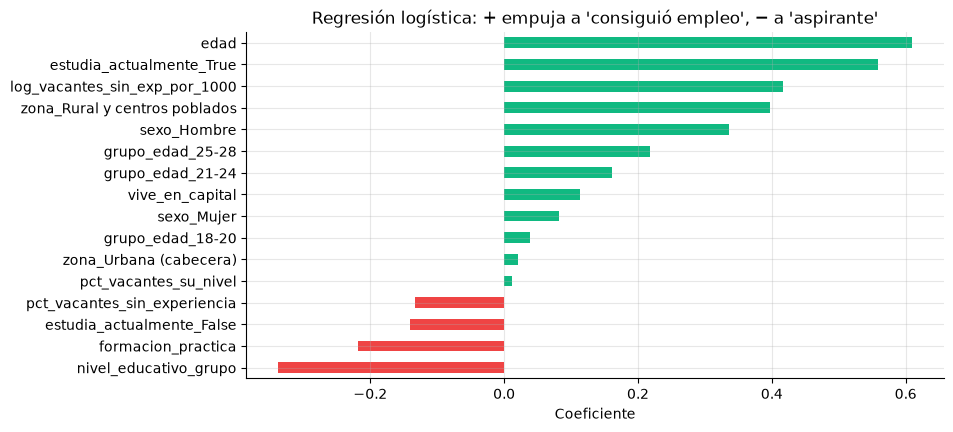

In [21]:
coeficientes = pd.Series(logistica.coef_[0], index=X.columns).sort_values()
ax = coeficientes.plot.barh(color=["#ef4444" if c < 0 else "#10b981" for c in coeficientes])
ax.set_title("Regresión logística: + empuja a 'consiguió empleo', − a 'aspirante'")
ax.set_xlabel("Coeficiente")
plt.show()

**Lectura:** la regresión logística queda **muy cerca** del árbol de profundidad 8 (AUC **0,69** frente a **0,71**; accuracy balanceada **63,9 %** frente a **65,7 %**). Que dos modelos tan distintos lleguen al mismo techo confirma que **el límite está en los datos**, no en el algoritmo. Los coeficientes cuentan la misma historia que el EDA:

- **Empujan a conseguir empleo:** más **edad**, **estar estudiando**, vivir en **zona rural** y más **vacantes sin experiencia por joven** en el departamento.
- **Empujan a quedarse como aspirante:** más **nivel educativo** y tener **formación práctica**. Es el hallazgo 1 del EDA: quien estudió más espera un empleo acorde y tarda más en aceptar el primero.

### 2.7 Conclusión del modelo

| | |
|---|---|
| **Modelo elegido** | Árbol de decisión balanceado, `max_depth=8` |
| **Desempeño en prueba** | AUC 0,71 · accuracy balanceada 65,7 % · detecta 69 % de los aspirantes, con 17,5 % de precisión |
| **Sin fuga de datos** | Ninguna variable de entrada depende de la respuesta (2.4) |
| **Sin sobreajuste** | 1,5 puntos de diferencia entre entrenamiento y prueba (2.5) |
| **Para qué sirve** | Como **filtro de priorización**: ordenar a quién llamar primero para orientación. **No** para decidir quién recibe o no un programa, porque 4 de cada 5 alertas son falsas |

Hipótesis de qué mejoraría el modelo (opción 3 de la guía): variables que la GEIH no tiene, como **horas de búsqueda, número de postulaciones, prácticas realizadas, área de formación** (no solo el nivel) y **acceso a internet o transporte**.

In [22]:
modelo_final = DecisionTreeClassifier(max_depth=8, class_weight="balanced", random_state=42).fit(X_train, y_train)
importancia_final = pd.Series(modelo_final.feature_importances_, index=X.columns).sort_values(ascending=False)
importancia_final.to_csv(os.path.join(SALIDA, "importancia_variables_modelo.csv"), header=["importancia"])
comparacion.to_csv(os.path.join(SALIDA, "comparacion_modelos.csv"))
importancia_final.head(6).round(3)

edad                             0.288
log_vacantes_sin_exp_por_1000    0.210
nivel_educativo_grupo            0.165
pct_vacantes_sin_experiencia     0.111
pct_vacantes_su_nivel            0.098
vive_en_capital                  0.033
dtype: float64

# Sección 3 — Técnica complementaria elegida (Unidad 7: minería de texto, anomalías o experimentación)

**Técnica elegida: detección de anomalías con Isolation Forest.** Nuestro dataset no tiene columnas de texto libre (todas son categorías codificadas por el DANE), y la guía recomienda anomalías en ese caso.

**Qué buscamos:** primeros empleos que **no se parecen a los demás** por la **combinación** de edad, nivel educativo e ingreso. En el Checkpoint 1 marcamos atípicos **una variable a la vez** (ingreso > percentil 99, ingreso = 0). Ahora queremos casos raros en conjunto: por ejemplo, un universitario de 27 años que gana $100.000 es raro aunque ese ingreso no sea atípico en general (muchos jóvenes de 18 años lo ganan).

**Para qué serviría:** (1) **calidad de datos:** registros que vale la pena revisar a mano; (2) **subempleo:** ver si hay jóvenes con estudios que entraron a trabajos muy por debajo de su formación, que es justo lo que la recomendación de formación debería evitar.

**Datos:** los **recién insertados** (`consiguio_empleo = 1`) con ingreso informado.

| Columna | Transformación |
|---|---|
| `ingreso_laboral_mensual` | Logaritmo (el ingreso va de miles a millones) |
| `edad` | Tal cual |
| `nivel_educativo_grupo` | Ordinal 0 (básica) … 5 (posgrado) |

Las tres se escalan con `StandardScaler`. Parámetros fijos: `n_estimators=200`, `random_state=42`. Lo que cambiamos entre configuraciones es la **contaminación** (qué % esperamos que sea anómalo) y si se incluyen los ingresos en 0.

In [23]:
from sklearn.ensemble import IsolationForest

insertados = datos[(datos["consiguio_empleo"] == 1) & datos["ingreso_laboral_mensual"].notna()].copy()
insertados["nivel_num"] = insertados["nivel_educativo_grupo"].cat.codes
COLUMNAS_ANOM = ["log_ingreso", "edad", "nivel_num"]
print("Recién insertados con ingreso informado:", len(insertados))
print("De ellos con ingreso = 0:", int(insertados["ingreso_cero"].sum()))

def correr_isolation_forest(base, contaminacion, semilla=42):
    base = base.copy()
    base["log_ingreso"] = np.log1p(base["ingreso_laboral_mensual"])
    Za = StandardScaler().fit_transform(base[COLUMNAS_ANOM])
    modelo = IsolationForest(contamination=contaminacion, n_estimators=200, random_state=semilla)
    return modelo.fit_predict(Za) == -1      # True = anomalía

Recién insertados con ingreso informado: 36731
De ellos con ingreso = 0: 264


### 3.1 Configuración A: con los ingresos en 0, contaminación 1 %

In [24]:
anom_a = correr_isolation_forest(insertados, 0.01)
print("Anomalías:", anom_a.sum())
print("Ingresos en 0 marcados como anomalía: %d de %d" % (insertados.loc[anom_a, "ingreso_cero"].sum(), insertados["ingreso_cero"].sum()))

Anomalías: 366
Ingresos en 0 marcados como anomalía: 264 de 264


**Lectura:** **los 264 ingresos en 0 salen como anomalía** y son el 72 % de lo marcado. El algoritmo redescubre la marca `ingreso_cero` del Checkpoint 1 (casi todos son trabajadores por cuenta propia sin ganancia ese mes) y no nos dice nada nuevo. **Decisión:** las siguientes configuraciones trabajan **sin los ingresos en 0**, que ya están marcados, para que el algoritmo busque otro tipo de rareza.

### 3.2 Configuraciones B, C y D: sin ingresos en 0, contaminación 1 %, 5 % y 10 %

In [25]:
base = insertados[~insertados["ingreso_cero"]].copy()
RANGOS_INGRESO = [0, 500_000, 1_400_000, 3_000_000, np.inf]
NOMBRES_RANGO = ["< 500 mil", "500 mil – 1,4 M", "1,4 – 3 M", "> 3 M"]

configuraciones = {"B · 1 %": 0.01, "C · 5 %": 0.05, "D · 10 %": 0.10}
resumen, marcas = [], {}
for nombre, cont in configuraciones.items():
    a = correr_isolation_forest(base, cont)
    marcas[nombre] = a
    an = base[a]
    resumen.append({
        "configuración": nombre, "anomalías": int(a.sum()),
        "ingreso_mediano_anomalías": an["ingreso_laboral_mensual"].median(),
        "ingreso_mediano_normales": base.loc[~a, "ingreso_laboral_mensual"].median(),
        "% con ingreso < 500 mil": (an["ingreso_laboral_mensual"] < 500_000).mean() * 100,
        "% posgrado": (an["nivel_educativo_grupo"] == "Posgrado").mean() * 100,
        "atípicos p99 del CP1 capturados": f"{int(an['ingreso_atipico'].sum())} de {int(base['ingreso_atipico'].sum())}",
    })
print("Base sin ingresos en 0:", len(base))
pd.DataFrame(resumen).set_index("configuración").round(1)

Base sin ingresos en 0: 36467


,anomalías,ingreso_mediano_anomalías,ingreso_mediano_normales,% con ingreso < 500 mil,% posgrado,atípicos p99 del CP1 capturados
configuración,,,,,,
B · 1 %,365,100000.0,1423000.0,63.8,35.9,80 de 288
C · 5 %,1824,240000.0,1423000.0,64.6,24.8,172 de 288
D · 10 %,3647,400000.0,1423500.0,55.8,16.9,269 de 288


In [26]:
for nombre in configuraciones:
    an = base[marcas[nombre]]
    print(f"\n{nombre} — nivel educativo × ingreso de las anomalías")
    print(pd.crosstab(an["nivel_educativo_grupo"],
                      pd.cut(an["ingreso_laboral_mensual"], RANGOS_INGRESO, labels=NOMBRES_RANGO)))


B · 1 % — nivel educativo × ingreso de las anomalías
ingreso_laboral_mensual  < 500 mil  > 3 M
nivel_educativo_grupo                    
Básica o menos                  89      0
Bachiller                       16      0
Técnico                         26      0
Tecnólogo                       21      0
Universitario                   79      3
Posgrado                         2    129

C · 5 % — nivel educativo × ingreso de las anomalías
ingreso_laboral_mensual  < 500 mil  500 mil – 1,4 M  1,4 – 3 M  > 3 M
nivel_educativo_grupo                                                
Básica o menos                 404                0         17     10
Bachiller                      192                0          0     11
Técnico                        143                0          3      9
Tecnólogo                       99               15          2     11
Universitario                  347               32          5     71
Posgrado                        11                6        159    

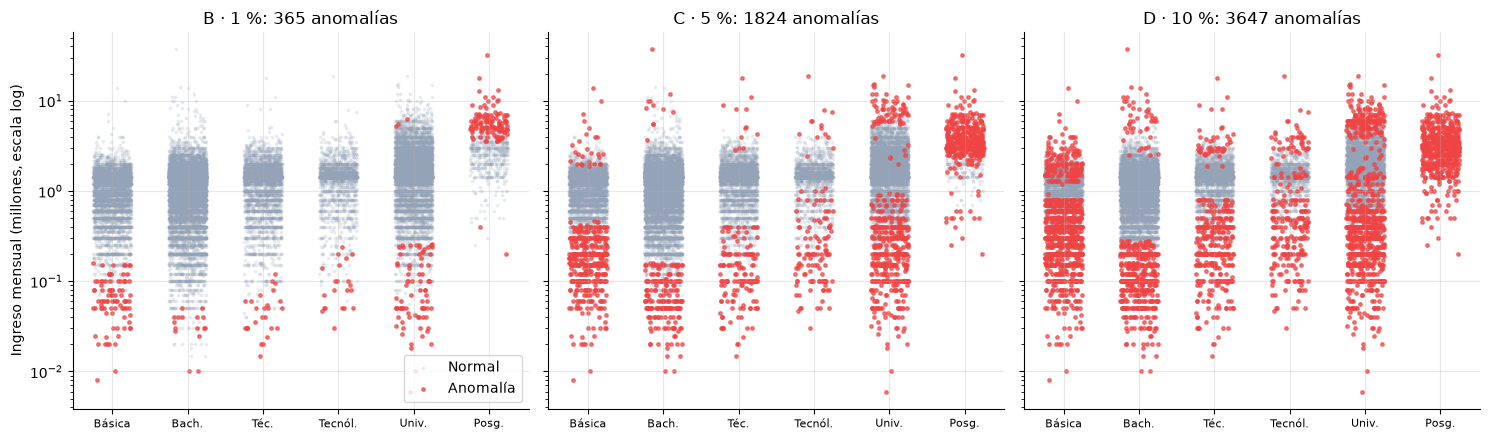

In [27]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)
for i, nombre in enumerate(configuraciones):
    a = marcas[nombre]
    jitter = np.random.default_rng(0).uniform(-.25, .25, len(base))
    ax[i].scatter(base.loc[~a, "nivel_num"] + jitter[~a], base.loc[~a, "ingreso_laboral_mensual"] / 1e6,
                  s=3, alpha=.15, color="#94a3b8", label="Normal")
    ax[i].scatter(base.loc[a, "nivel_num"] + jitter[a], base.loc[a, "ingreso_laboral_mensual"] / 1e6,
                  s=6, alpha=.7, color="#ef4444", label="Anomalía")
    ax[i].set_yscale("log")
    ax[i].set_xticks(range(6), ["Básica", "Bach.", "Téc.", "Tecnól.", "Univ.", "Posg."], fontsize=8)
    ax[i].set_title(f"{nombre}: {a.sum()} anomalías")
ax[0].set_ylabel("Ingreso mensual (millones, escala log)")
ax[0].legend(loc="lower right")
plt.tight_layout()
plt.show()

In [28]:
an_b = base[marcas["B · 1 %"]]
bajo = an_b[an_b["ingreso_laboral_mensual"] < 500_000]
print("Anomalías con ingreso < $500.000:", len(bajo))
print("  por cuenta propia:", int((bajo["posicion_ocupacional"] == "Cuenta propia").sum()))
print("  con 18 a 20 años:", int((bajo["edad"] <= 20).sum()))

univ = bajo[bajo["nivel_educativo_grupo"] == "Universitario"]
print("\nUniversitarios con ingreso < $500.000:", len(univ))
print("  estudian actualmente:", int(univ["estudia_actualmente"].sum()))
print("  con 18 a 20 años:", int((univ["edad"] <= 20).sum()))
print("  ingreso mediano: $%.0f" % univ["ingreso_laboral_mensual"].median())

Anomalías con ingreso < $500.000: 233
  por cuenta propia: 178
  con 18 a 20 años: 114

Universitarios con ingreso < $500.000: 79
  estudian actualmente: 75
  con 18 a 20 años: 54
  ingreso mediano: $70000


### 3.3 ¿Es estable? Misma configuración B con otras semillas

In [29]:
estabilidad = []
for semilla in [1, 2, 3]:
    a = correr_isolation_forest(base, 0.01, semilla)
    estabilidad.append({"semilla": semilla, "anomalías": int(a.sum()),
                        "coinciden con semilla 42": int((a & marcas["B · 1 %"]).sum())})
pd.DataFrame(estabilidad)

,semilla,anomalías,coinciden con semilla 42
0,1,365,294
1,2,363,329
2,3,365,308


### 3.4 Comparación de las configuraciones y elección

| Configuración | Qué encuentra | ¿Sirve? |
|---|---|---|
| **A · con ingresos en 0 (1 %, 366 casos)** | Casi solo los ingresos en 0 | No: repite una regla que ya teníamos |
| **B · 1 % (365 casos)** | Dos tipos claros: **ingresos de menos de $500.000** (233 casos, en todos los niveles) y **posgrados con más de $3 M** (129) | **Sí, la elegimos**: pocos casos y todos con una razón clara para revisarlos |
| **C · 5 % (1.824 casos)** | Lo mismo de B, más ingresos de 1,4 a 3 M en posgrado y más ingresos bajos en todos los niveles | Demasiados para revisar a mano y empieza a marcar casos normales |
| **D · 10 % (3.647 casos)** | Ya marca ingresos de 500 mil a 1,4 M en básica, que son normales | No: el 10 % es más de lo que razonablemente es "raro" |

Las configuraciones están **anidadas**: todo lo que marca B también lo marcan C y D. Subir la contaminación solo agrega casos menos raros. La configuración B también es **razonablemente estable**: con otras semillas coincide en **80 a 90 %** de los casos.

**Lo que encontramos (configuración B):**

1. **El primer "empleo" de muchos es un rebusque.** **233 de las 365 anomalías ganan menos de $500.000** al mes (un tercio del salario mínimo), y **178 de ellas trabajan por cuenta propia**. 114 tienen entre 18 y 20 años, lo que coincide con el hallazgo 3 del EDA (los de 18 a 20 son los más vulnerables).
2. **Los "universitarios" que ganan poco no son profesionales subempleados.** Esperábamos encontrar subempleo de profesionales, pero de los **79 universitarios con menos de $500.000**, **75 todavía estudian** y **54 tienen entre 18 y 20 años** (ganan $70.000 de mediana). Son estudiantes con un trabajo pequeño mientras hacen la carrera. Esto destapa un **límite de nuestros datos**: en la GEIH, el nivel educativo "universitario" incluye a quien **está cursando** la carrera, no solo a quien se graduó. Hay que tenerlo en cuenta al leer el hallazgo 1 del EDA (los universitarios se insertan menos).
3. **Posgrados con altos ingresos:** son raros porque **hay muy pocos jóvenes con posgrado**, no porque sean un error. Aquí el algoritmo marca lo **poco frecuente**, no lo sospechoso.
### 3.5 Ficha de limitaciones y riesgos de la técnica

| Riesgo | Qué puede pasar | Qué hacemos |
|---|---|---|
| **"Raro" no es "error"** | Isolation Forest marca lo **poco frecuente**. Los posgrados salen como anomalía solo porque son pocos | Cada caso marcado se **revisa a mano** antes de corregir o borrar algo. No borramos ninguna fila por esta técnica |
| **La contaminación la decidimos nosotros** | Con 1 % salen 365 casos y con 10 % salen 3.644. El número de anomalías no es un hallazgo, es una elección | Comparamos 3 niveles y justificamos el 1 % por el tamaño revisable y porque cada caso tiene una razón clara |
| **Falsos positivos** | Un ingreso bajo puede ser real (medio tiempo, primer mes de un negocio) y no un problema | Lo tratamos como **alerta para revisar**, no como conclusión |
| **Falsos negativos** | Solo usamos 3 variables. Un error en otra columna (por ejemplo, el sector) no se detecta | Dejamos documentadas las columnas usadas. Para otras columnas siguen valiendo las reglas del Checkpoint 1 |
| **Depende de la semilla** | Con otra semilla cambia entre 10 y 20 % de los casos del borde | Reportamos la estabilidad (3.3). Los casos más extremos salen siempre |
| **Uso sin revisión humana** | Si alguien usara esta lista para **excluir** jóvenes de un programa o para decir que "mienten" en la encuesta, castigaría justo a los más vulnerables (los de ingreso casi nulo) | La lista **solo** sirve para revisar calidad de datos y para estudiar el subempleo, **nunca para decidir sobre personas** |

In [30]:
base["anomalia_isolation_forest"] = marcas["B · 1 %"]
columnas = ["mes", "id_hogar", "orden", "departamento", "edad", "sexo", "nivel_educativo_grupo",
            "ingreso_laboral_mensual", "posicion_ocupacional", "sector"]
base.loc[base["anomalia_isolation_forest"], columnas].to_csv(os.path.join(SALIDA, "anomalias_primer_empleo.csv"), index=False)
print("Guardado: data/processed/anomalias_primer_empleo.csv →", int(base["anomalia_isolation_forest"].sum()), "casos")

Guardado: data/processed/anomalias_primer_empleo.csv → 365 casos


# Resumen del Checkpoint 2

| Sección | Resultado principal | Qué aporta a la pregunta |
|---|---|---|
| **1. Segmentación** | 3 tipos de departamento: **A** entran y formal (15), **B** cuesta entrar (8), **C** entran pero informal (10). k=3 por el codo y por tamaño; el jerárquico coincide en 29 de 33 | **Hacia qué regiones orientar** (A) y qué programa necesita cada región (primer empleo en B, formalización en C) |
| **2. Modelo predictivo** | Árbol balanceado de profundidad 8: AUC 0,71, detecta 69 % de los aspirantes, **sin fuga** (con fuga daría 99,8 %) y sin sobreajuste | La **edad**, la **competencia por vacantes** del departamento y el **nivel educativo** son lo que más pesa. Sirve para priorizar, no para decidir |
| **3. Anomalías** | Isolation Forest al 1 %: 365 primeros empleos raros; **233 ganan menos de $500.000**, casi todos por cuenta propia | Muchos primeros empleos son un **rebusque**. Y advierte que el nivel «universitario» de la GEIH incluye a quien todavía estudia |

Estos resultados se juntan en el producto final (Checkpoint 3) con el EDA del Checkpoint 1.